# Graph 7: Predicted vs actual (one test week)
Run `01_data_processing.ipynb` and `08_modelling.ipynb` first.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
saved = joblib.load("processed/model_results.joblib")
best_name, predictions = saved["best_name"], saved["predictions"]
test, y_test = saved["test"], saved["y_test"]

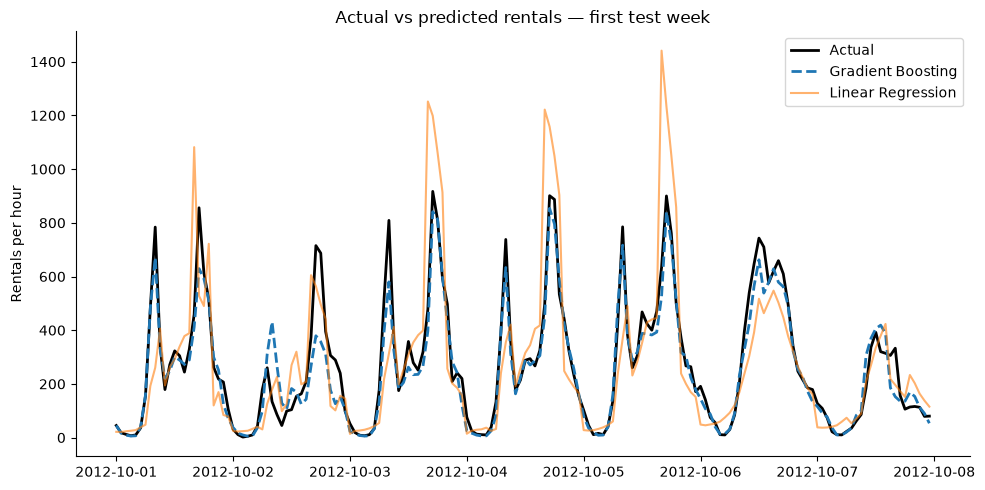

In [3]:
week = test["datetime"] < test["datetime"].min() + pd.Timedelta(days=7)
plt.plot(test.loc[week, "datetime"], y_test[week], label="Actual", lw=2, color="black")
plt.plot(test.loc[week, "datetime"], predictions[best_name][week.values], label=best_name, lw=2, ls="--")
plt.plot(test.loc[week, "datetime"], predictions["Linear Regression"][week.values], label="Linear Regression", alpha=0.6)
plt.title("Actual vs predicted rentals — first test week"); plt.ylabel("Rentals per hour"); plt.legend()
plt.tight_layout(); plt.savefig("figures/07_actual_vs_predicted.png", dpi=150); plt.show()